# Chapter 88: Households, Marriage, Fertility, and Intergenerational Transfers

This notebook reruns four of the chapter's hypothetical household examples: fallback power in Nash bargaining, comparative advantage at home, children as old-age insurance, and private gifts that undo a public transfer. A few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def stacked_bar(ax, names, parts, part_labels, colors=None, ylabel="Value", total_marker=True, fmt=None):
    """Bars built from signed parts (one list per part), with a marker at each bar's net total.

    Positive parts stack upward from zero and negative parts downward, so a bar with a
    negative substitution part and a positive income part shows both pieces and the net.
    """
    parts = [[float(v) for v in p] for p in parts]
    n = len(names)
    xs = np.arange(n)
    colors = colors or [color(i) for i in range(len(parts))]
    pos_base, neg_base = np.zeros(n), np.zeros(n)
    for p, lab, col in zip(parts, part_labels, colors):
        p = np.array(p)
        base = np.where(p >= 0, pos_base, neg_base)
        ax.bar(xs, p, bottom=base, color=color(col), width=0.55, label=lab)
        pos_base = pos_base + np.where(p >= 0, p, 0)
        neg_base = neg_base + np.where(p < 0, p, 0)
    totals = np.sum(np.array(parts), axis=0)
    if total_marker:
        ax.scatter(xs, totals, marker="D", s=46, color=PALETTE["ink"], zorder=5)
        for x, t in zip(xs, totals):
            ax.annotate(f"net {fmt(t) if fmt else f'{t:,.2f}'}", (x, t), xytext=(14, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=LABEL_SIZE,
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, n - 0.4 + 0.5)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def nash_bargaining_choice(options, dS=0.0, dF=0.0):
    """Nash products of a finite list of (u_S, u_F) options; returns (products, best indices).

    Principle: nash-bargaining-solution. Book (ch013): (80, 40) and (40, 80) both give 3,200, a tie.
    """
    prods = [(a - dS) * (b - dF) for a, b in options]
    top = max(prods)
    return prods, [i for i, v in enumerate(prods) if v == top]


def household_specialization(w, h, hours, need, plan="specialize"):
    """Two partners meet a care need and sell the rest of their hours.

    Principle: gains-from-marital-specialization (chapter 88). Book: w = (32, 45), h = (2, 1.5),
    12 hours each, need 18: costs 16 and 30; equal split income 240 + 270 = 510; specialization
    96 + 540 = 636; with h_B = 4 Ben cares and income is 337.50 + 384 = 721.50.
    plan "equal": each makes need / 2; "specialize": the lower w/h partner makes all the need
    (assumes it fits in their hours). Returns care hours, market hours, earnings, total, costs.
    """
    costs = [w[i] / h[i] for i in range(2)]
    if plan == "equal":
        units = [need / 2, need / 2]
    else:
        lo = 0 if costs[0] <= costs[1] else 1
        units = [need if i == lo else 0.0 for i in range(2)]
    care = [units[i] / h[i] for i in range(2)]
    market = [hours - care[i] for i in range(2)]
    earn = [w[i] * market[i] for i in range(2)]
    return {"costs": costs, "units": units, "care_hours": care, "market_hours": market, "earnings": earn,
            "total": sum(earn)}


def prob_at_least_one(p, n):
    """1 - (1 - p)^n."""
    return 1.0 - (1.0 - p) ** n


def linked_budget_crowd_out(YD, YR, g_desired, b):
    """Altruistic parent adjusts the gift g = max(0, g_desired - b) after a public transfer b.

    Principle: altruistic-transfer-neutrality (chapter 88). Book: YD 84,000, YR 26,000, desired gift
    12,000: b = 4,500 gives g = 7,500 and (72,000, 38,000); b = 15,000 gives g = 0, (69,000, 41,000)
    and crowd-out 12,000. Returns gift, c_D, c_R, crowd_out.
    """
    g = max(0.0, g_desired - b)
    return {"gift": g, "c_D": YD - b - g, "c_R": YR + b + g, "crowd_out": g_desired - g}


plt.rcParams.update(HOUSE_RC)


games = SimpleNamespace(nash_bargaining_choice=nash_bargaining_choice)


production = SimpleNamespace(household_specialization=household_specialization)


choice = SimpleNamespace(prob_at_least_one=prob_at_least_one)


public = SimpleNamespace(linked_budget_crowd_out=linked_budget_crowd_out)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'cooperative-household-bargaining': {'X': (78, 52),
                                      'Y': (60, 70),
                                      'dA': 35,
                                      'dB': 32,
                                      'N_X': 860,
                                      'N_Y': 950,
                                      'dA_reform': 45,
                                      'N_X_reform': 660,
                                      'N_Y_reform': 570},
 'gains-from-marital-specialization': {'hours': 12,
                                       'w': (32, 45),
                                       'h': (2, 1.5),
                                       'need': 18,
                                       'cost_A': 16,
                                       'cost_B': 30,
                                       'equal_total': 510,
                                       'spec_total': 636,
                                       'gain': 126,
                                       'hB_tech': 4,
                                       'tech_total': 721.5},
 'old-age-security-fertility-motive': {'q': 0.55,
                                       'target': 0.92,
                                       'P3': 0.908875,
                                       'P4': 0.958994,
                                       'q_mig': 0.35,
                                       'P4_mig': 0.821494,
                                       'P6_mig': 0.924581,
                                       'n_mig': 6,
                                       'target_low': 0.85},
 'altruistic-transfer-neutrality': {'YD': 84000,
                                    'YR': 26000,
                                    'g': 12000,
                                    'cD': 72000,
                                    'cR': 38000,
                                    'b': 4500,
                                    'g_b': 7500,
                                    'b_big': 15000,
                                    'cD_big': 69000,
                                    'cR_big': 41000,
                                    'crowd_big': 12000},
 'constructed': {'cooperative-household-bargaining': {'dA': [40, 61], 'dB': [40]},
                 'gains-from-marital-specialization': {'hB': [3]},
                 'old-age-security-fertility-motive': {'q': [0.75], 'target': [0.95]},
                 'altruistic-transfer-neutrality': {'b': [12000]}}}


def bargaining_picture(da=35, db=32):
    dA, dB = da, db
    b = BV["cooperative-household-bargaining"]
    X, Y = b["X"], b["Y"]
    prods, _ = games.nash_bargaining_choice([X, Y], dA, dB)
    feas = [X[0] >= dA and X[1] >= dB, Y[0] >= dA and Y[1] >= dB]
    fig, ax = new_figure()
    for (u, v), name, col, ok in ((X, "X", "teal", feas[0]), (Y, "Y", "gold", feas[1])):
        if ok:
            ax.fill_between([dA, u], dB, v, color=PALETTE[col], alpha=0.18, linewidth=0)
        mark(ax, u, v, f"{name} ({u}, {v})", col=col, dx=8, dy=4)
    mark(ax, dA, dB, f"d = ({dA}, {dB})", col="terracotta", dx=-6, dy=-6, ha="right", va="top")
    ax.set_xlim(20, 95)
    ax.set_ylim(20, 85)
    ax.set_xlabel("Ana's utility U_A")
    ax.set_ylabel("Ben's utility U_B")
    nx = f"({X[0]} - {dA})({X[1]} - {dB}) = {X[0] - dA}({X[1] - dB}) = {num(prods[0], 0)}"
    ny = f"({Y[0]} - {dA})({Y[1]} - {dB}) = {Y[0] - dA}({Y[1] - dB}) = {num(prods[1], 0)}"
    if all(feas):
        if prods[0] > prods[1]:
            choice_txt, verdict = "X", f"X has the larger Nash product, {num(prods[0], 0)} against {num(prods[1], 0)}"
        elif prods[1] > prods[0]:
            choice_txt, verdict = "Y", f"Y has the larger Nash product, {num(prods[1], 0)} against {num(prods[0], 0)}"
        else:
            choice_txt, verdict = "Tie (X or Y)", f"the two Nash products tie at {num(prods[0], 0)}"
    elif feas[0]:
        choice_txt = "X (Y infeasible)"
        verdict = f"Y gives Ana {Y[0]}, below her fallback {dA}, so only X is individually rational"
    elif feas[1]:
        choice_txt = "Y (X infeasible)"
        verdict = f"X gives Ben {X[1]}, below his fallback {dB}, so only Y is individually rational"
    else:
        choice_txt, verdict = "Neither", "neither allocation beats both fallbacks"
    metrics = {"N_X": num(prods[0], 0), "N_Y": num(prods[1], 0), "Chosen allocation": choice_txt}
    steps = [f"N_X = {nx}", f"N_Y = {ny}", f"Result: {verdict}"]
    interp = (f"With fallbacks d_A = {dA} and d_B = {dB}, N_X = {nx} and N_Y = {ny}. So {verdict}. Resources and "
              f"the two utility pairs are fixed; only the fallbacks move.")
    areas = " and ".join(f"{n} {num(p, 0)}" for n, p, ok in zip("XY", prods, feas) if ok) or "none"
    alt = (f"Utility plane with X at (78, 52), Y at (60, 70) and the disagreement point ({dA}, {dB}); shaded "
           f"gain rectangles for feasible allocations have areas {areas}. Chosen: {choice_txt}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def specialization_picture(hb=1.5, plan="specialize"):
    hB = hb
    b = BV["gains-from-marital-specialization"]
    w, need, hours = b["w"], b["need"], b["hours"]
    h = (b["h"][0], hB)
    r = production.household_specialization(w, h, hours, need, plan)
    eq = production.household_specialization(w, h, hours, need, "equal")
    sp = production.household_specialization(w, h, hours, need, "specialize")
    care, mkt, earn = r["care_hours"], r["market_hours"], r["earnings"]
    fig, (ax1, ax2) = new_figure(ncols=2)
    stacked_bar(ax1, ["Ana", "Ben"], [care, mkt], ["care hours", "market hours"], colors=["gold", "teal"],
                ylabel="Hours per week", total_marker=False)
    ax1.set_xlabel("Partner")
    for i in range(2):
        if care[i] > 0:
            label(ax1, i, care[i] / 2, f"care {num(care[i])}", dx=0, dy=0, ha="center", va="center")
        label(ax1, i, care[i] + mkt[i] / 2, f"market {num(mkt[i])}", dx=0, dy=0, ha="center", va="center")
    ax1.set_ylim(0, 14.5)
    ax1.set_xlim(-0.6, 1.6)
    bar_compare(ax2, ["Equal split", "Specialize"], [eq["total"], sp["total"]], colors=["grey", "navy"],
                value_labels=[money(eq["total"]), money(sp["total"])], ylabel="Weekly market income ($)",
                xlabel="Allocation")
    ax2.set_ylim(0, 860)
    cA, cB = r["costs"]
    who = "Ana" if cA <= cB else "Ben"
    gain = sp["total"] - eq["total"]
    metrics = {"Ana's cost per care unit": money(cA), "Ben's cost per care unit": money(cB),
               "Income under this plan": money(r["total"]), "Gain from specializing": money(gain)}
    steps = [f"Opportunity costs: Ana 32 / 2 = {money(cA)}, Ben 45 / {num(hB)} = {money(cB)}",
             f"Ana: {num(r['units'][0], 1)} units take {num(care[0])} hours; {num(mkt[0])} market hours x 32 = {money(earn[0])}",
             f"Ben: {num(r['units'][1], 1)} units take {num(care[1])} hours; {num(mkt[1])} market hours x 45 = {money(earn[1])}",
             f"Total = {money(earn[0])} + {money(earn[1])} = {money(r['total'])}",
             f"Specializing beats the equal split by {money(sp['total'])} - {money(eq['total'])} = {money(gain)}"]
    plan_txt = "Each makes 9 care units" if plan == "equal" else f"{who}, the lower-cost carer, makes all 18 units"
    interp = (f"With Ben producing {num(hB)} units an hour, care costs Ana 32 / 2 = {num(cA)} and Ben 45 / {num(hB)} = {num(cB)} dollars of "
              f"forgone earnings per unit, so {who} has the comparative advantage in care. {plan_txt}: income is "
              f"{money(earn[0])} + {money(earn[1])} = {money(r['total'])}. Specializing gains {money(gain)} over "
              f"the equal split, with the same 18 care units.")
    alt = (f"Left: stacked care and market hours for Ana and Ben. Right: income {money(eq['total'])} under an equal "
           f"split and {money(sp['total'])} under specialization.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def security_picture(q=0.55, target=0.92):
    ns = np.arange(1, 9)
    ps = [choice.prob_at_least_one(q, int(n)) for n in ns]
    need = next((int(n) for n, p in zip(ns, ps) if p >= target), None)
    fig, ax = new_figure()
    cols = [PALETTE["gold"] if need is not None and n == need else PALETTE["teal"] for n in ns]
    ax.bar(ns, ps, color=cols, width=0.65)
    hline(ax, target, f"target {pct(target, 0)}", col="terracotta", x_frac=0.02 if (need or 9) >= 3 else 0.62)
    if need is not None:
        label(ax, need, ps[need - 1], pct(ps[need - 1], 2), dx=0, dy=4, ha="center", box=True)
    ax.set_ylim(0, 1.12)
    ax.set_xlabel("Number of children n")
    ax.set_ylabel("Chance at least one can support")
    p_prev = ps[need - 2] if need and need > 1 else None
    miss = 1 - q
    metrics = {"P(3 children)": pct(ps[2], 2), "P(4 children)": pct(ps[3], 2),
               "Children needed": str(need) if need else "more than 8"}
    steps = [f"P(n) = 1 - (1 - {num(q)})^n = 1 - {num(miss)}^n"]
    if need and need > 1:
        steps.append(f"n = {need - 1}: 1 - {num(miss)}^{need - 1} = {pct(p_prev, 2)}, below {pct(target, 0)}")
    if need:
        steps.append(f"n = {need}: 1 - {num(miss)}^{need} = {pct(ps[need - 1], 2)}, at or above {pct(target, 0)}")
        steps.append(f"Smallest family meeting the target: {need} children")
    interp = (f"Each child can support with chance {num(q)}, so the chance at least one of n can is 1 - "
              f"{num(miss)}^n; for example 1 - {num(miss)}^3 = {num(ps[2], 4)}. ")
    if need and need > 1:
        kids = "1 child" if need - 1 == 1 else f"{need - 1} children"
        interp += (f"With {kids} it is {pct(p_prev, 2)}, short of {pct(target, 0)}; with {need} it is "
                   f"{pct(ps[need - 1], 2)}, so the security rule asks for {need} children.")
    elif need == 1:
        interp += f"One child already gives {pct(ps[0], 2)}, enough for {pct(target, 0)}."
    alt = (f"Bars of the chance of at least one supporter for 1 to 8 children at q = {num(q)}, with a target line at "
           f"{pct(target, 0)}; the first bar to reach it is n = {need}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def neutrality_picture(b=4_500):
    v = BV["altruistic-transfer-neutrality"]
    r = public.linked_budget_crowd_out(v["YD"], v["YR"], v["g"], b)
    g, cD, cR, co = r["gift"], r["c_D"], r["c_R"], r["crowd_out"]
    fig, ax = new_figure()
    names = ["Parent", "Child"]
    parts = [[v["YD"], v["YR"]], [-b, b], [-g, g]]
    stacked_bar(ax, names, parts, ["own income", "public transfer", "private gift"],
                colors=["grey", "navy", "gold"], ylabel="Dollars per year", total_marker=False)
    for i, c in enumerate((cD, cR)):
        mark(ax, i, c, f"consumes {money(c, 0)}", col="ink", dx=16, dy=0, va="center")
    ax.set_ylim(-35_000, 100_000)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    ax.set_xlim(-0.6, 2.2)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Household member")
    if b == 0:
        regime = "with no program there is nothing to crowd out, and the gift alone sets consumption"
    elif b < v["g"]:
        regime = (f"the gift falls one for one, so consumption stays at {money(cD, 0)} and {money(cR, 0)}: full "
                  f"crowd-out")
    elif b == v["g"]:
        regime = "the gift just reaches zero: the boundary case, still full crowd-out"
    else:
        regime = (f"the gift cannot fall below zero, so only {money(co, 0)} is crowded out and the remaining "
                  f"{money(b - co, 0)} moves consumption")
    metrics = {"Private gift": money(g, 0), "Parent consumes c_D": money(cD, 0), "Child consumes c_R": money(cR, 0),
               "Crowded out": money(co, 0)}
    steps = [f"Gift g = max(0, 12,000 - {num(b, 0)}) = {num(g, 0)}",
             f"c_D = 84,000 - {num(b, 0)} - {num(g, 0)} = {num(cD, 0)}",
             f"c_R = 26,000 + {num(b, 0)} + {num(g, 0)} = {num(cR, 0)}",
             f"Crowd-out = 12,000 - {num(g, 0)} = {num(co, 0)}"]
    interp = (f"The parent wants the child to consume 38,000, so with a public transfer of {money(b, 0)} the gift "
              f"becomes {money(g, 0)}. Then c_D = 84,000 - {num(b, 0)} - {num(g, 0)} = {num(cD, 0)} and c_R = "
              f"26,000 + {num(b, 0)} + {num(g, 0)} = {num(cR, 0)}: {regime}.")
    alt = (f"Stacked bars of the parent's and child's resources: own income, a public transfer of {money(b, 0)} and "
           f"a gift of {money(g, 0)}; consumption {money(cD, 0)} and {money(cR, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Cooperative household bargaining: fallback power picks the allocation

Allocation X gives utilities (78, 52) and Y gives (60, 70); fallbacks are (35, 32).

$$N_X=(78-35)(52-32)=43(20)=860, \qquad N_Y=(60-35)(70-32)=25(38)=950$$

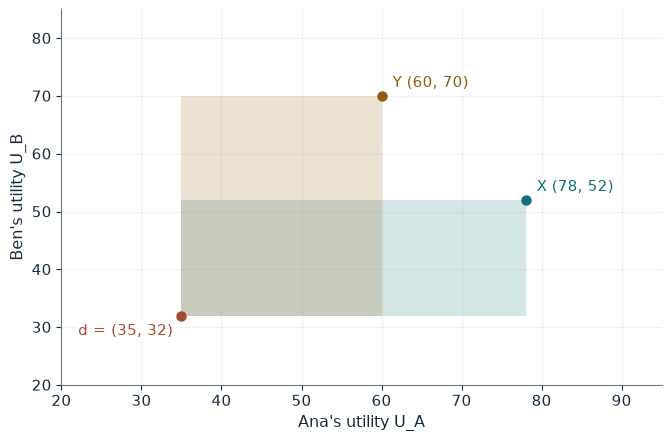

N_X                860
N_Y                950
Chosen allocation  Y

Worked steps:
  1. N_X = (78 - 35)(52 - 32) = 43(20) = 860
  2. N_Y = (60 - 35)(70 - 32) = 25(38) = 950
  3. Result: Y has the larger Nash product, 950 against 860

With fallbacks d_A = 35 and d_B = 32, N_X = (78 - 35)(52 - 32) = 43(20) = 860 and N_Y = (60 - 35)(70 - 32) = 25(38) = 950. So Y has the larger Nash product, 950 against 860. Resources and the two utility pairs are fixed; only the fallbacks move.


In [2]:
show(bargaining_picture(da=35, db=32))

Change one input, `da`, and hold the others at the book's values:

In [3]:
sweep(bargaining_picture, 'da', [35, 40, 45, 61], {'db': 32}, ['N_X', 'N_Y', 'Chosen allocation'])

da | N_X | N_Y | Chosen allocation
35 | 860 | 950 | Y
40 | 760 | 760 | Tie (X or Y)
45 | 660 | 570 | X
61 | 340 | -38 | X (Y infeasible)


Y wins at the book's fallbacks. Raising Ana's fallback to 45 gives 660 against 570, so X wins; at 40 the products tie at 760, and at 61 Y is no longer individually rational for Ana.

## 2. Gains from marital specialization: comparative advantage at home

Each partner has 12 hours; Ana earns \$32 or makes 2 care units an hour, Ben earns \$45 or makes 1.5. The household needs 18 units.

$$\frac{32}{2}=\$16, \qquad \frac{45}{1.5}=\$30$$

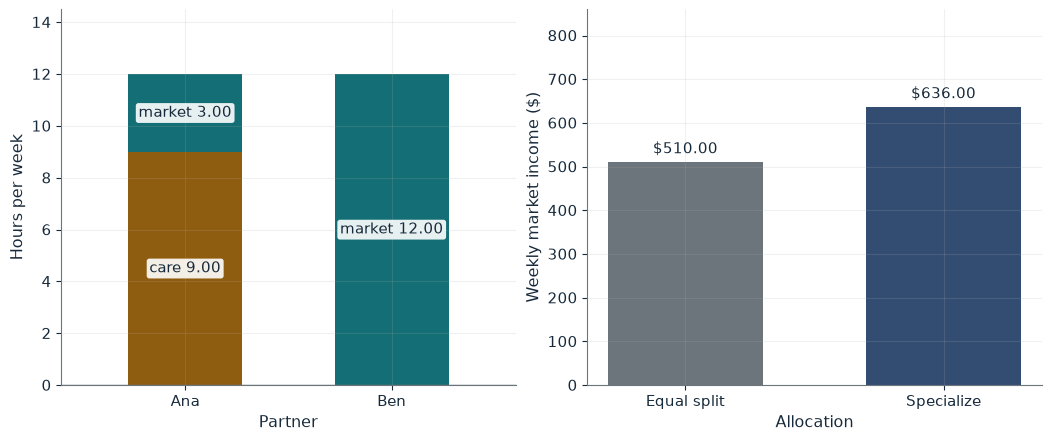

Ana's cost per care unit  $16.00
Ben's cost per care unit  $30.00
Income under this plan    $636.00
Gain from specializing    $126.00

Worked steps:
  1. Opportunity costs: Ana 32 / 2 = $16.00, Ben 45 / 1.50 = $30.00
  2. Ana: 18.0 units take 9.00 hours; 3.00 market hours x 32 = $96.00
  3. Ben: 0.0 units take 0.00 hours; 12.00 market hours x 45 = $540.00
  4. Total = $96.00 + $540.00 = $636.00
  5. Specializing beats the equal split by $636.00 - $510.00 = $126.00

With Ben producing 1.50 units an hour, care costs Ana 32 / 2 = 16.00 and Ben 45 / 1.50 = 30.00 dollars of forgone earnings per unit, so Ana has the comparative advantage in care. Ana, the lower-cost carer, makes all 18 units: income is $96.00 + $540.00 = $636.00. Specializing gains $126.00 over the equal split, with the same 18 care units.


In [4]:
show(specialization_picture(hb=1.5, plan='specialize'))

Change one input, `hb`, and hold the others at the book's values:

In [5]:
sweep(specialization_picture, 'hb', [1.5, 3, 4], {'plan': 'specialize'}, ["Ben's cost per care unit", 'Income under this plan', 'Gain from specializing'])

hb | Ben's cost per care unit | Income under this plan | Gain from specializing
1.5 | $30.00 | $636.00 | $126.00
3 | $15.00 | $654.00 | $9.00
4 | $11.25 | $721.50 | $42.75


Ana has the lower cost per care unit, so specializing raises income from \$510 to \$636. When Ben makes 3 or 4 units an hour his cost falls below \$16 and he should do the care.

## 3. Old-age-security fertility motive: how many children for security?

Each child can support with chance q = 0.55; parents want a 92 percent chance.

$$1-(1-0.55)^3=1-0.45^3=90.8875\%, \qquad 1-0.45^4=95.8994\%$$

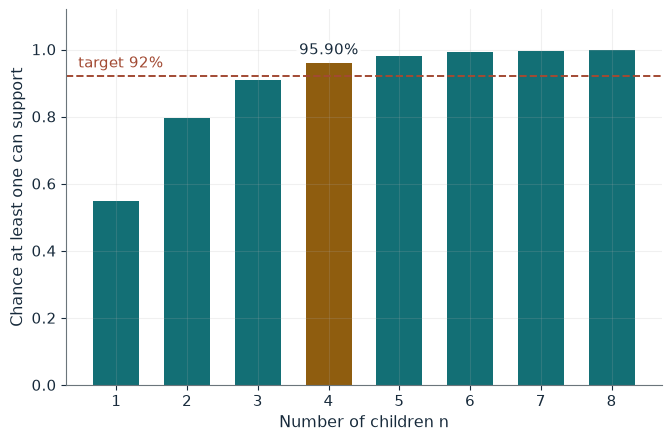

P(3 children)    90.89%
P(4 children)    95.90%
Children needed  4

Worked steps:
  1. P(n) = 1 - (1 - 0.55)^n = 1 - 0.45^n
  2. n = 3: 1 - 0.45^3 = 90.89%, below 92%
  3. n = 4: 1 - 0.45^4 = 95.90%, at or above 92%
  4. Smallest family meeting the target: 4 children

Each child can support with chance 0.55, so the chance at least one of n can is 1 - 0.45^n; for example 1 - 0.45^3 = 0.9089. With 3 children it is 90.89%, short of 92%; with 4 it is 95.90%, so the security rule asks for 4 children.


In [6]:
show(security_picture(q=0.55, target=0.92))

Change one input, `q`, and hold the others at the book's values:

In [7]:
sweep(security_picture, 'q', [0.35, 0.55, 0.75], {'target': 0.92}, ['P(3 children)', 'P(4 children)', 'Children needed'])

q | P(3 children) | P(4 children) | Children needed
0.35 | 72.54% | 82.15% | 6
0.55 | 90.89% | 95.90% | 4
0.75 | 98.44% | 99.61% | 2


Four children are needed at q = 0.55, six when migration lowers q to 0.35, and only two at 0.75.

## 4. Altruistic-transfer neutrality: when public transfers are crowded out

The parent earns 84,000, the child 26,000, and the parent's desired gift is 12,000.

$$c_D=84{,}000-4{,}500-7{,}500=\$72{,}000, \qquad c_R=26{,}000+4{,}500+7{,}500=\$38{,}000$$

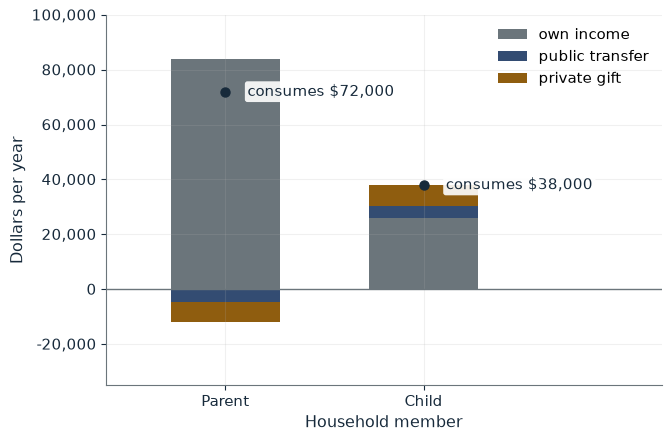

Private gift         $7,500
Parent consumes c_D  $72,000
Child consumes c_R   $38,000
Crowded out          $4,500

Worked steps:
  1. Gift g = max(0, 12,000 - 4,500) = 7,500
  2. c_D = 84,000 - 4,500 - 7,500 = 72,000
  3. c_R = 26,000 + 4,500 + 7,500 = 38,000
  4. Crowd-out = 12,000 - 7,500 = 4,500

The parent wants the child to consume 38,000, so with a public transfer of $4,500 the gift becomes $7,500. Then c_D = 84,000 - 4,500 - 7,500 = 72,000 and c_R = 26,000 + 4,500 + 7,500 = 38,000: the gift falls one for one, so consumption stays at $72,000 and $38,000: full crowd-out.


In [8]:
show(neutrality_picture(b=4_500))

Change one input, `b`, and hold the others at the book's values:

In [9]:
sweep(neutrality_picture, 'b', [0, 4500, 12000, 15000], {}, ['Private gift', 'Parent consumes c_D', 'Child consumes c_R', 'Crowded out'])

b | Private gift | Parent consumes c_D | Child consumes c_R | Crowded out
0 | $12,000 | $72,000 | $38,000 | $0
4500 | $7,500 | $72,000 | $38,000 | $4,500
12000 | $0 | $72,000 | $38,000 | $12,000
15000 | $0 | $69,000 | $41,000 | $12,000


Up to 12,000 the gift falls dollar for dollar and consumption does not move. At 15,000 the gift hits zero, only 12,000 is crowded out and the child consumes 41,000.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

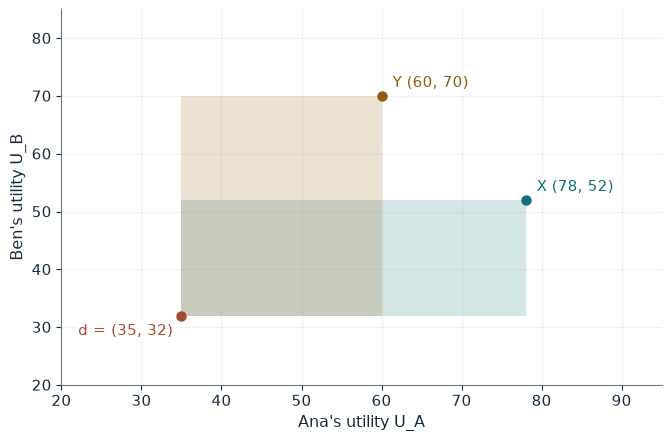

N_X                860
N_Y                950
Chosen allocation  Y

Worked steps:
  1. N_X = (78 - 35)(52 - 32) = 43(20) = 860
  2. N_Y = (60 - 35)(70 - 32) = 25(38) = 950
  3. Result: Y has the larger Nash product, 950 against 860

With fallbacks d_A = 35 and d_B = 32, N_X = (78 - 35)(52 - 32) = 43(20) = 860 and N_Y = (60 - 35)(70 - 32) = 25(38) = 950. So Y has the larger Nash product, 950 against 860. Resources and the two utility pairs are fixed; only the fallbacks move.


In [10]:
show(bargaining_picture(da=35, db=32))

## Practice

**1.** With fallbacks (45, 40), which allocation is chosen?

<details><summary>Answer</summary>

N_X = 33 x 12 = 396 and N_Y = 15 x 30 = 450, so Y.

</details>

**2.** With h_B = 4 and an equal split, what is income?

<details><summary>Answer</summary>

Ana: 4.5 care hours, 7.5 x 32 = 240; Ben: 2.25 care hours, 9.75 x 45 = 438.75; total 678.75.

</details>

**3.** With q = 0.35 and a 95 percent target, how many children are needed?

<details><summary>Answer</summary>

1 - 0.65^6 = 92.46% falls short; 1 - 0.65^7 = 95.10%, so 7.

</details>